# Indian Stocks Value-at-Risk (VaR) — Live Calculation (Enhanced)

**Live notebook** using real NSE data via `yfinance`.

**Portfolio:** 10 large-cap Indian stocks (equal-weighted)  
**Horizon:** 10 trading days  
**Confidence levels:** 95% and 99%  
**Portfolio value:** ₹1 Crore  

### What's included
1. Live / historical NSE data download  
2. **Historical**, **Parametric** (EWMA & sample), **Student-t Monte Carlo**, and **Filtered Historical Simulation** VaR  
3. **Expected Shortfall (ES / CVaR)** at 95% and 99%  
4. Rolling Historical VaR **backtest** with exceedance counts and **Kupiec test**  
5. Diagnostics, correlation, price paths, P&L distributions  
6. Horizon sensitivity + non-overlapping robustness check  
7. Conclusions computed directly from results (no hard-coded text)


## 1. Install & Import


In [1]:
# Uncomment if running in a fresh environment
# !pip install yfinance pandas numpy matplotlib scipy seaborn

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, t as student_t, skew, kurtosis, chi2
from datetime import datetime

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

print("Libraries loaded.")
print(f"Notebook run: {datetime.now().strftime('%Y-%m-%d %H:%M')}")


Libraries loaded.
Notebook run: 2026-10-29 19:41


## 2. Define the Indian Portfolio

We use popular NSE large-cap stocks across sectors (suffix `.NS` = National Stock Exchange).


In [2]:
tickers = [
    "RELIANCE.NS",   # Energy / Conglomerate
    "TCS.NS",        # IT
    "HDFCBANK.NS",   # Banking
    "INFY.NS",       # IT
    "ICICIBANK.NS",  # Banking
    "HINDUNILVR.NS", # FMCG
    "SBIN.NS",       # Banking (PSU)
    "BHARTIARTL.NS", # Telecom
    "ITC.NS",        # FMCG
    "LT.NS",         # Infrastructure / Engineering
]

# Parameters
start_date = "2019-01-01"
end_date   = datetime.today().strftime("%Y-%m-%d")
rolling_window = 10          # 10 trading days
confidence_levels = [0.95, 0.99]
portfolio_value = 10_000_000 # ₹1 Crore
simulations = 50_000
ewma_lambda = 0.94           # RiskMetrics standard
student_df = 5               # degrees of freedom for Student-t MC

print("Tickers:", tickers)
print(f"Period: {start_date} → {end_date}")
print(f"Horizon: {rolling_window} days | Confidence: {[f'{c:.0%}' for c in confidence_levels]} | Value: ₹{portfolio_value:,.0f}")
print(f"EWMA λ: {ewma_lambda} | Student-t df: {student_df} | MC sims: {simulations:,}")


Tickers: ['RELIANCE.NS', 'TCS.NS', 'HDFCBANK.NS', 'INFY.NS', 'ICICIBANK.NS', 'HINDUNILVR.NS', 'SBIN.NS', 'BHARTIARTL.NS', 'ITC.NS', 'LT.NS']
Period: 2019-01-01 → 2026-10-29
Horizon: 10 days | Confidence: ['95%', '99%'] | Value: ₹10,000,000
EWMA λ: 0.94 | Student-t df: 5 | MC sims: 50,000


## 3. Download Data from Yahoo Finance


In [3]:
print("Downloading adjusted-close prices ...")
raw = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False, progress=True)

if isinstance(raw.columns, pd.MultiIndex):
    adj_close = raw["Adj Close"].copy()
else:
    adj_close = raw[["Adj Close"]].copy()

adj_close = adj_close.dropna(axis=1, how="all")
tickers = list(adj_close.columns)
n = len(tickers)

print(f"\nLoaded {n} stocks, {len(adj_close)} trading days")
print(f"Date range: {adj_close.index[0].date()} → {adj_close.index[-1].date()}")
adj_close.tail()


[*********************100%***********************]  10 of 10 completed


Loaded 10 stocks, 1933 trading days
Date range: 2019-01-01 → 2026-10-28


Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,SBIN.NS,TCS.NS
Date,,,,,,,,,,
2026-10-22,1895.000000,694.049988,1828.300049,1398.500000,1153.349976,258.899994,3638.300049,1184.500000,970.000000,2506.899902
2026-10-23,1892.099976,692.799988,1814.699951,1394.199951,1153.800049,257.899994,3647.000000,1190.000000,958.599976,2530.000000
2026-10-26,1917.500000,688.049988,1818.599976,1403.000000,1166.000000,260.500000,3680.000000,1201.800049,960.799988,2535.000000
2026-10-27,1978.800049,680.200012,1818.000000,1386.900024,1163.000000,260.000000,3665.100098,1196.199951,945.099976,2496.899902
2026-10-28,1948.099976,685.299988,1815.800049,1377.599976,1123.150024,259.500000,3801.300049,1158.000000,956.799988,2460.000000


## 4. Log Returns & Equal-Weighted Portfolio


In [4]:
# Daily log returns
log_returns = np.log(adj_close / adj_close.shift(1)).dropna()

# Equal weights
weights = np.array([1.0 / n] * n)
print("Equal weights:", np.round(weights, 4))

# Portfolio daily returns
port_daily = (log_returns * weights).sum(axis=1)

# Rolling N-day returns (overlapping)
rolling_returns = port_daily.rolling(window=rolling_window).sum().dropna()
print(f"Rolling {rolling_window}-day observations (overlapping): {len(rolling_returns)}")

# Non-overlapping N-day returns (robustness)
non_overlap = port_daily.groupby(np.arange(len(port_daily)) // rolling_window).sum()
non_overlap = non_overlap.iloc[:-1] if len(port_daily) % rolling_window != 0 else non_overlap
print(f"Non-overlapping {rolling_window}-day observations: {len(non_overlap)}")

rolling_returns.describe().round(4)


Equal weights: [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Rolling 10-day observations (overlapping): 1923
Non-overlapping 10-day observations: 193


count    1923.0000
mean        0.0044
std         0.0338
min        -0.3288
25%        -0.0135
50%         0.0053
75%         0.0245
max         0.1436
dtype: float64

## 5. Calculate VaR & Expected Shortfall

### Methods
- **Historical** – empirical percentile of past rolling returns  
- **Parametric (sample)** – normal approx with sample covariance  
- **Parametric (EWMA)** – normal approx with RiskMetrics EWMA volatility  
- **Student-t Monte Carlo** – correlated multivariate Student-t scenarios  
- **Filtered Historical Simulation (FHS)** – historical residuals scaled by current EWMA vol  

Also compute **Expected Shortfall (ES / CVaR)** = mean loss beyond VaR.


In [5]:
def historical_var_es(returns, conf, value):
    pct = 100 * (1 - conf)
    var = -np.percentile(returns, pct) * value
    threshold = np.percentile(returns, pct)
    es = -returns[returns <= threshold].mean() * value
    return var, es

def parametric_var_es(vol_annual, conf, horizon, value, mu_daily=0.0):
    z = norm.ppf(conf)
    scale = np.sqrt(horizon / 252)
    # drift term (usually small)
    mu_h = mu_daily * horizon
    var = (-mu_h + vol_annual * z * scale) * value
    # ES under normality: vol * phi(z) / (1-conf) * scale
    es = (-mu_h + vol_annual * norm.pdf(z) / (1 - conf) * scale) * value
    return var, es

# ----- Shared quantities -----
cov_daily = log_returns.cov().values
cov_annual = cov_daily * 252
port_vol_annual_sample = np.sqrt(weights.T @ cov_annual @ weights)
mu = log_returns.mean().values
port_mu = weights @ mu
port_vol_daily_sample = np.sqrt(weights.T @ cov_daily @ weights)

# ----- EWMA portfolio volatility -----
# EWMA variance of portfolio daily returns
ewma_var = port_daily.ewm(alpha=1 - ewma_lambda, adjust=False).var().iloc[-1]
port_vol_daily_ewma = np.sqrt(ewma_var)
port_vol_annual_ewma = port_vol_daily_ewma * np.sqrt(252)

print(f"Sample annual vol: {port_vol_annual_sample:.2%}")
print(f"EWMA annual vol (λ={ewma_lambda}): {port_vol_annual_ewma:.2%}")

# ----- Student-t Monte Carlo (correlated) -----
# Cholesky of correlation matrix, scale by vols, then Student-t shocks
vols = log_returns.std().values
corr = log_returns.corr().values
# regularise correlation if needed
eigvals = np.linalg.eigvalsh(corr)
if eigvals.min() < 1e-8:
    corr = corr + np.eye(n) * 1e-6
chol = np.linalg.cholesky(corr)

rng = np.random.default_rng(seed=42)
# multivariate Student-t: Z ~ N(0,I), then scale by sqrt(df / chi2)
z_norm = rng.standard_normal((simulations, n))
chi2_draws = rng.chisquare(student_df, size=simulations)
t_shocks = z_norm * np.sqrt(student_df / chi2_draws[:, None])
# correlated t shocks
t_corr = t_shocks @ chol.T
# scale by individual vols and add mean; sum over horizon under independent increments
# for horizon h: mean * h + sqrt(h) * portfolio residual
# Build simulated daily portfolio return under t, then scale
sim_daily_port = (t_corr * vols) @ weights   # one-day portfolio residual under t
sim_returns_t = port_mu * rolling_window + sim_daily_port * np.sqrt(rolling_window)
sim_pnl_t = sim_returns_t * portfolio_value

# ----- Filtered Historical Simulation -----
# Standardise historical portfolio returns by rolling EWMA vol, then re-scale by current EWMA
ewma_vol_series = port_daily.ewm(alpha=1 - ewma_lambda, adjust=False).std()
# avoid div by zero at start
ewma_vol_series = ewma_vol_series.replace(0, np.nan).dropna()
aligned = port_daily.reindex(ewma_vol_series.index)
std_resid = (aligned / ewma_vol_series).dropna()
# multi-day FHS: sample blocks of length horizon from standardised residuals
# simpler FHS: sum of h independent draws from residual pool, then scale by current vol
n_resid = len(std_resid)
fhs_sims = []
for _ in range(simulations):
    idx = rng.integers(0, n_resid, size=rolling_window)
    path = std_resid.values[idx].sum()   # sum of standardised residuals over horizon
    fhs_sims.append(path)
fhs_sims = np.array(fhs_sims)
# re-scale by current EWMA daily vol * sqrt is already embedded in sum of std residuals
# actually: each residual is r_t / σ_t, so sum of h residuals ~ sum (r)/σ_current if σ constant
fhs_returns = port_mu * rolling_window + fhs_sims * port_vol_daily_ewma
fhs_pnl = fhs_returns * portfolio_value

# ----- Compute VaR & ES for both confidence levels -----
rows = []
for conf in confidence_levels:
    pct = 100 * (1 - conf)

    # Historical
    h_var, h_es = historical_var_es(rolling_returns, conf, portfolio_value)

    # Parametric sample
    p_var, p_es = parametric_var_es(port_vol_annual_sample, conf, rolling_window, portfolio_value, port_mu)

    # Parametric EWMA
    e_var, e_es = parametric_var_es(port_vol_annual_ewma, conf, rolling_window, portfolio_value, port_mu)

    # Student-t MC
    t_var = -np.percentile(sim_pnl_t, pct)
    t_thresh = np.percentile(sim_pnl_t, pct)
    t_es = -sim_pnl_t[sim_pnl_t <= t_thresh].mean()

    # FHS
    f_var = -np.percentile(fhs_pnl, pct)
    f_thresh = np.percentile(fhs_pnl, pct)
    f_es = -fhs_pnl[fhs_pnl <= f_thresh].mean()

    for method, var, es in [
        ("Historical", h_var, h_es),
        ("Parametric (sample)", p_var, p_es),
        ("Parametric (EWMA)", e_var, e_es),
        ("Student-t Monte Carlo", t_var, t_es),
        ("Filtered HS", f_var, f_es),
    ]:
        rows.append({
            "Confidence": f"{conf:.0%}",
            "Method": method,
            "VaR (₹)": int(round(var)),
            "VaR (%)": round(var / portfolio_value * 100, 3),
            "ES (₹)": int(round(es)),
            "ES (%)": round(es / portfolio_value * 100, 3),
        })

results = pd.DataFrame(rows)
print("=" * 80)
print("VALUE-AT-RISK & EXPECTED SHORTFALL RESULTS")
print("=" * 80)
print(results.to_string(index=False))
print("=" * 80)

# Store key numbers for dynamic conclusion
hist_95 = results.loc[(results["Confidence"] == "95%") & (results["Method"] == "Historical"), "VaR (₹)"].values[0]
hist_99 = results.loc[(results["Confidence"] == "99%") & (results["Method"] == "Historical"), "VaR (₹)"].values[0]
es_95 = results.loc[(results["Confidence"] == "95%") & (results["Method"] == "Historical"), "ES (₹)"].values[0]
es_99 = results.loc[(results["Confidence"] == "99%") & (results["Method"] == "Historical"), "ES (₹)"].values[0]

results


Sample annual vol: 17.00%
EWMA annual vol (λ=0.94): 15.24%
VALUE-AT-RISK & EXPECTED SHORTFALL RESULTS
Confidence                Method  VaR (₹)  VaR (%)  ES (₹)  ES (%)
       95%            Historical   417494    4.175  762651   7.627
       95%   Parametric (sample)   513408    5.134  654942   6.549
       95%     Parametric (EWMA)   455601    4.556  582450   5.824
       95% Student-t Monte Carlo   641372    6.414  933920   9.339
       95%           Filtered HS   416377    4.164  757772   7.578
       99%            Historical   765211    7.652 1639943  16.399
       99%   Parametric (sample)   744238    7.442  859017   8.590
       99%     Parametric (EWMA)   662481    6.625  765350   7.653
       99% Student-t Monte Carlo  1079928   10.799 1462377  14.624
       99%           Filtered HS   696593    6.966 1724193  17.242


,Confidence,Method,VaR (₹),VaR (%),ES (₹),ES (%)
0,95%,Historical,417494,4.175,762651,7.627
1,95%,Parametric (sample),513408,5.134,654942,6.549
2,95%,Parametric (EWMA),455601,4.556,582450,5.824
3,95%,Student-t Monte Carlo,641372,6.414,933920,9.339
4,95%,Filtered HS,416377,4.164,757772,7.578
5,99%,Historical,765211,7.652,1639943,16.399
6,99%,Parametric (sample),744238,7.442,859017,8.590
7,99%,Parametric (EWMA),662481,6.625,765350,7.653
8,99%,Student-t Monte Carlo,1079928,10.799,1462377,14.624
9,99%,Filtered HS,696593,6.966,1724193,17.242


## 6. Portfolio Return Diagnostics


In [6]:
diag = pd.Series({
    "Mean (10d return)": rolling_returns.mean(),
    "Std Dev": rolling_returns.std(),
    "Skewness": skew(rolling_returns),
    "Excess Kurtosis": kurtosis(rolling_returns),
    "Min": rolling_returns.min(),
    "Max": rolling_returns.max(),
    "5th percentile": np.percentile(rolling_returns, 5),
    "1st percentile": np.percentile(rolling_returns, 1),
}).round(6)

print("Rolling-return diagnostics:")
print(diag.to_string())
print()
print("Note: Strong negative skew + high excess kurtosis → fat left tail.")
print("Historical / FHS / Student-t capture extremes better than pure normal methods.")
diag


Rolling-return diagnostics:
Mean (10d return)     0.004424
Std Dev               0.033846
Skewness             -1.885363
Excess Kurtosis      15.001641
Min                  -0.328849
Max                   0.143650
5th percentile       -0.041749
1st percentile       -0.076521

Note: Strong negative skew + high excess kurtosis → fat left tail.
Historical / FHS / Student-t capture extremes better than pure normal methods.


Mean (10d return)     0.004424
Std Dev               0.033846
Skewness             -1.885363
Excess Kurtosis      15.001641
Min                  -0.328849
Max                   0.143650
5th percentile       -0.041749
1st percentile       -0.076521
dtype: float64

## 7. Individual Stock Snapshot


In [7]:
last_prices = adj_close.iloc[-1]
ann_vol = log_returns.std() * np.sqrt(252) * 100

snapshot = pd.DataFrame({
    "Last Close (₹)": last_prices.round(2),
    "Ann. Volatility (%)": ann_vol.round(1),
})
snapshot.index = [t.replace(".NS", "") for t in snapshot.index]
snapshot = snapshot.sort_values("Ann. Volatility (%)", ascending=False)
print(snapshot.to_string())
snapshot


            Last Close (₹)  Ann. Volatility (%)
SBIN                956.80                 31.0
ICICIBANK          1377.60                 28.8
INFY               1123.15                 28.3
BHARTIARTL         1948.10                 27.8
RELIANCE           1158.00                 27.5
LT                 3801.30                 27.5
HDFCBANK            685.30                 24.9
TCS                2460.00                 24.7
ITC                 259.50                 24.1
HINDUNILVR         1815.80                 22.5


,Last Close (₹),Ann. Volatility (%)
SBIN,956.80,31.0
ICICIBANK,1377.60,28.8
INFY,1123.15,28.3
BHARTIARTL,1948.10,27.8
RELIANCE,1158.00,27.5
LT,3801.30,27.5
HDFCBANK,685.30,24.9
TCS,2460.00,24.7
ITC,259.50,24.1
HINDUNILVR,1815.80,22.5


## 8. Rolling Historical VaR Backtest & Kupiec Test

We compute a rolling 1-day 95% Historical VaR using a 250-day lookback, then count exceedances
and run the **Kupiec unconditional coverage test**.

$$H_0: \text{true exception rate} = 1 - c \qquad LR_{uc} = -2\ln\frac{(1-p)^{n-x}p^{x}}{(1-\hat{p})^{n-x}\hat{p}^{x}} \sim \chi^2_1$$


Backtest window: 2020-01-13 → 2026-10-27
Observations: 1681
Exceptions: 99  (5.89% vs expected 5.00%)

Kupiec LR_uc = 2.6546
p-value       = 0.1033
Reject H0 at 5%? NO — exception rate consistent with 95% VaR


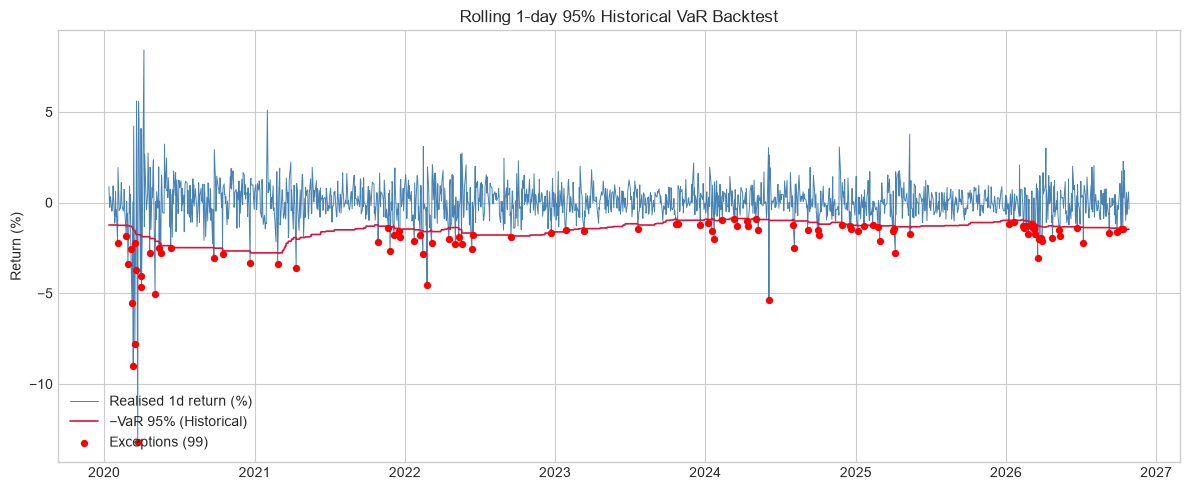

Observations        1681
Exceptions            99
Exception rate    0.0589
Expected rate       0.05
Kupiec LR         2.6546
p-value           0.1033
Reject H0 (5%)     False
dtype: object

In [8]:
# ----- 1-day Historical VaR rolling backtest -----
lookback = 250
conf_bt = 0.95
alpha_bt = 1 - conf_bt

var_series = []
actual_series = []
dates = []

port_arr = port_daily.values
idx = port_daily.index

for i in range(lookback, len(port_arr) - 1):
    window = port_arr[i - lookback:i]
    var_1d = -np.percentile(window, 100 * alpha_bt)
    actual = port_arr[i]          # next-day realised return
    var_series.append(var_1d)
    actual_series.append(actual)
    dates.append(idx[i])

var_series = np.array(var_series)
actual_series = np.array(actual_series)
exceptions = actual_series < -var_series
n_obs = len(exceptions)
n_exc = exceptions.sum()
exc_rate = n_exc / n_obs

print(f"Backtest window: {dates[0].date()} → {dates[-1].date()}")
print(f"Observations: {n_obs}")
print(f"Exceptions: {n_exc}  ({exc_rate:.2%} vs expected {alpha_bt:.2%})")

# Kupiec unconditional coverage test
p = alpha_bt
p_hat = exc_rate if exc_rate > 0 else 1e-10
if n_exc == 0:
    lr_uc = -2 * n_obs * np.log(1 - p)
else:
    lr_uc = -2 * (
        (n_obs - n_exc) * np.log(1 - p) + n_exc * np.log(p)
        - (n_obs - n_exc) * np.log(1 - p_hat) - n_exc * np.log(p_hat)
    )
p_value = 1 - chi2.cdf(lr_uc, df=1)
reject = p_value < 0.05

print(f"\nKupiec LR_uc = {lr_uc:.4f}")
print(f"p-value       = {p_value:.4f}")
print(f"Reject H0 at 5%? {'YES — model is misspecified' if reject else 'NO — exception rate consistent with 95% VaR'}")

# Plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates, actual_series * 100, lw=0.7, label="Realised 1d return (%)", color="steelblue")
ax.plot(dates, -var_series * 100, lw=1.2, label="−VaR 95% (Historical)", color="crimson")
exc_dates = [dates[i] for i in range(n_obs) if exceptions[i]]
exc_vals = actual_series[exceptions] * 100
ax.scatter(exc_dates, exc_vals, color="red", s=18, zorder=5, label=f"Exceptions ({n_exc})")
ax.set_title("Rolling 1-day 95% Historical VaR Backtest")
ax.set_ylabel("Return (%)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

backtest_summary = pd.Series({
    "Observations": n_obs,
    "Exceptions": int(n_exc),
    "Exception rate": round(exc_rate, 4),
    "Expected rate": alpha_bt,
    "Kupiec LR": round(lr_uc, 4),
    "p-value": round(p_value, 4),
    "Reject H0 (5%)": reject,
})
backtest_summary


## 9. Visualisations


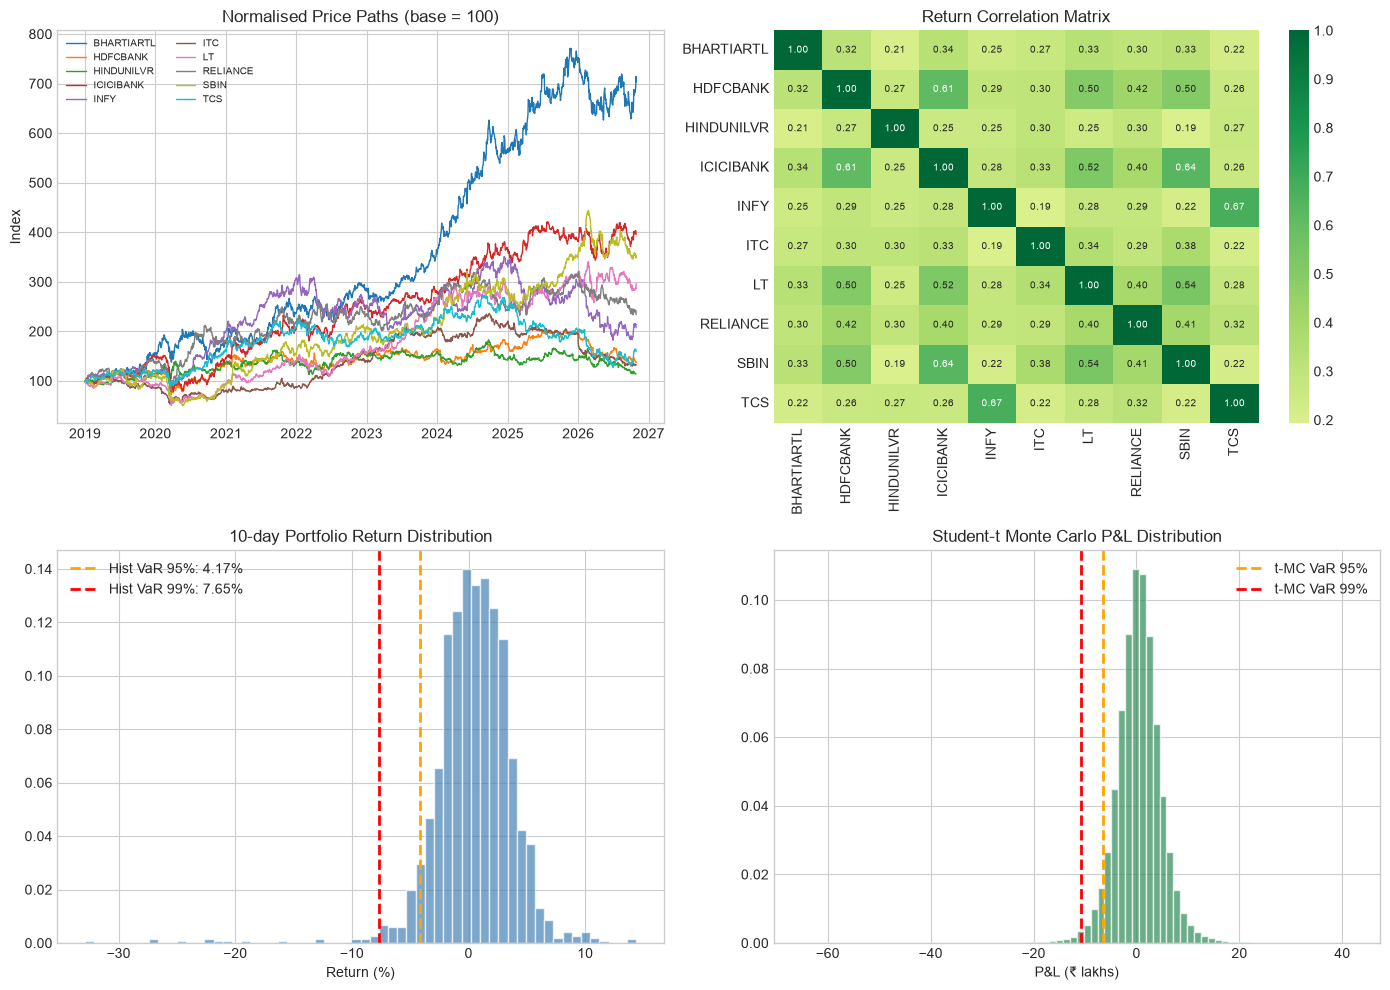

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (0,0) Normalised price paths
normed = adj_close / adj_close.iloc[0] * 100
for col in normed.columns:
    axes[0, 0].plot(normed.index, normed[col], lw=1, label=col.replace(".NS", ""))
axes[0, 0].set_title("Normalised Price Paths (base = 100)")
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 0].set_ylabel("Index")

# (0,1) Correlation heatmap
corr_mat = log_returns.corr()
corr_mat.index = [c.replace(".NS", "") for c in corr_mat.index]
corr_mat.columns = corr_mat.index
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            ax=axes[0, 1], annot_kws={"size": 7})
axes[0, 1].set_title("Return Correlation Matrix")

# (1,0) Histogram of 10-day rolling returns + VaR lines
axes[1, 0].hist(rolling_returns * 100, bins=60, density=True, alpha=0.7, color="steelblue", edgecolor="white")
for conf, color in [(0.95, "orange"), (0.99, "red")]:
    v = -np.percentile(rolling_returns, 100 * (1 - conf)) * 100
    axes[1, 0].axvline(-v, color=color, ls="--", lw=2, label=f"Hist VaR {conf:.0%}: {v:.2f}%")
axes[1, 0].set_title("10-day Portfolio Return Distribution")
axes[1, 0].set_xlabel("Return (%)")
axes[1, 0].legend()

# (1,1) Student-t MC P&L distribution
axes[1, 1].hist(sim_pnl_t / 1e5, bins=80, density=True, alpha=0.7, color="seagreen", edgecolor="white")
for conf, color in [(0.95, "orange"), (0.99, "red")]:
    v = -np.percentile(sim_pnl_t, 100 * (1 - conf)) / 1e5
    axes[1, 1].axvline(-v, color=color, ls="--", lw=2, label=f"t-MC VaR {conf:.0%}")
axes[1, 1].set_title("Student-t Monte Carlo P&L Distribution")
axes[1, 1].set_xlabel("P&L (₹ lakhs)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 10. Sensitivity — VaR vs Horizon + Non-overlapping Robustness

Under the normal assumption VaR scales roughly with $\sqrt{N}$. We also compare overlapping vs non-overlapping Historical VaR.


 Horizon (days)  Hist overlap (₹)  Hist non-overlap (₹)  Param sample (₹)  Param EWMA (₹)  Student-t MC (₹)
              1            144218                144218            176181          157900            212274
              5            330618                341463            393952          353076            462574
             10            417494                404969            557132          499325            641372
             20            542518                431048            787903          706152            881425
             40            779084                598490           1114263          998649           1195298
             60           1048932                695615           1364688         1223090           1415794


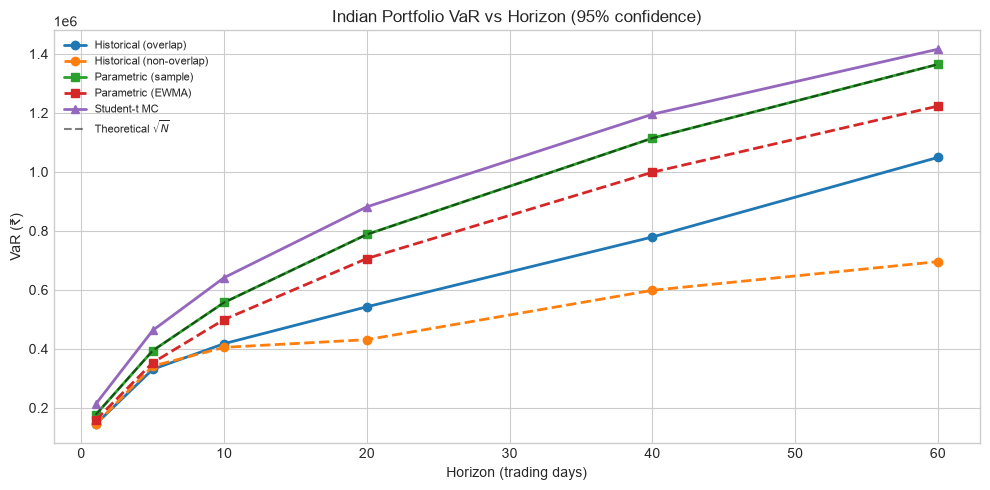

,Horizon (days),Hist overlap (₹),Hist non-overlap (₹),Param sample (₹),Param EWMA (₹),Student-t MC (₹)
0,1,144218,144218,176181,157900,212274
1,5,330618,341463,393952,353076,462574
2,10,417494,404969,557132,499325,641372
3,20,542518,431048,787903,706152,881425
4,40,779084,598490,1114263,998649,1195298
5,60,1048932,695615,1364688,1223090,1415794


In [10]:
horizons = [1, 5, 10, 20, 40, 60]
sens_rows = []

for h in horizons:
    # Historical overlapping
    roll_h = port_daily.rolling(window=h).sum().dropna()
    hist_h = -np.percentile(roll_h, 5) * portfolio_value

    # Historical non-overlapping
    no = port_daily.groupby(np.arange(len(port_daily)) // h).sum()
    if len(port_daily) % h != 0:
        no = no.iloc[:-1]
    hist_no = -np.percentile(no, 5) * portfolio_value if len(no) > 10 else np.nan

    # Parametric sample
    scale = np.sqrt(h / 252)
    para_h = port_vol_annual_sample * norm.ppf(0.95) * scale * portfolio_value

    # Parametric EWMA
    ewma_h = port_vol_annual_ewma * norm.ppf(0.95) * scale * portfolio_value

    # Student-t MC (reuse shocks scaled)
    sim_h = port_mu * h + sim_daily_port * np.sqrt(h)
    mc_h = -np.percentile(sim_h * portfolio_value, 5)

    sens_rows.append({
        "Horizon (days)": h,
        "Hist overlap (₹)": int(round(hist_h)),
        "Hist non-overlap (₹)": int(round(hist_no)) if not np.isnan(hist_no) else None,
        "Param sample (₹)": int(round(para_h)),
        "Param EWMA (₹)": int(round(ewma_h)),
        "Student-t MC (₹)": int(round(mc_h)),
    })

sens_df = pd.DataFrame(sens_rows)
print(sens_df.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sens_df["Horizon (days)"], sens_df["Hist overlap (₹)"], "o-", label="Historical (overlap)", lw=2)
ax.plot(sens_df["Horizon (days)"], sens_df["Hist non-overlap (₹)"], "o--", label="Historical (non-overlap)", lw=2)
ax.plot(sens_df["Horizon (days)"], sens_df["Param sample (₹)"], "s-", label="Parametric (sample)", lw=2)
ax.plot(sens_df["Horizon (days)"], sens_df["Param EWMA (₹)"], "s--", label="Parametric (EWMA)", lw=2)
ax.plot(sens_df["Horizon (days)"], sens_df["Student-t MC (₹)"], "^-", label="Student-t MC", lw=2)

one_day = sens_df.loc[0, "Param sample (₹)"]
ax.plot(sens_df["Horizon (days)"], one_day * np.sqrt(sens_df["Horizon (days)"]),
        "k--", alpha=0.5, label=r"Theoretical $\sqrt{N}$")

ax.set_xlabel("Horizon (trading days)")
ax.set_ylabel("VaR (₹)")
ax.set_title("Indian Portfolio VaR vs Horizon (95% confidence)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

sens_df


## 11. Conclusions (computed from results)


In [11]:
print("=" * 80)
print("CONCLUSIONS")
print("=" * 80)
print(f"""
Portfolio: equal-weighted 10 NSE large-caps | Value: ₹{portfolio_value:,.0f}
Horizon: {rolling_window} trading days | Data: {adj_close.index[0].date()} → {adj_close.index[-1].date()}

1. HISTORICAL VaR (most model-free)
   • 95% 10-day VaR ≈ ₹{hist_95:,}  ({hist_95/portfolio_value:.2%} of portfolio)
   • 99% 10-day VaR ≈ ₹{hist_99:,}  ({hist_99/portfolio_value:.2%} of portfolio)
   • Corresponding ES (tail average): 95% ≈ ₹{es_95:,} | 99% ≈ ₹{es_99:,}

2. DISTRIBUTIONAL FEATURES
   • Skewness = {diag['Skewness']:.2f}  |  Excess kurtosis = {diag['Excess Kurtosis']:.1f}
   → Fat left tail; normal-based Parametric VaR can understate risk.
   → Student-t MC and Filtered HS sit between Historical and pure-normal numbers.

3. EWMA vs SAMPLE VOL
   • Sample annual vol = {port_vol_annual_sample:.2%}
   • EWMA annual vol (λ={ewma_lambda}) = {port_vol_annual_ewma:.2%}
   → Current risk level is {'higher' if port_vol_annual_ewma > port_vol_annual_sample else 'lower'} than the long-run average.

4. BACKTEST (1-day 95% Historical VaR, {lookback}-day lookback)
   • Exceptions: {n_exc} / {n_obs}  (rate {exc_rate:.2%} vs expected 5%)
   • Kupiec LR = {lr_uc:.3f}, p-value = {p_value:.3f}
   → H0 of correct coverage is {'REJECTED' if reject else 'NOT rejected'} at the 5% level.

5. PRACTICAL TAKEAWAY
   Use Historical or Filtered HS VaR/ES for limit setting; keep Student-t MC as a
   stress-aware complement. Re-run this notebook periodically — the numbers above
   are computed live from the latest data.
""")
print("=" * 80)


CONCLUSIONS

Portfolio: equal-weighted 10 NSE large-caps | Value: ₹10,000,000
Horizon: 10 trading days | Data: 2019-01-01 → 2026-10-28

1. HISTORICAL VaR (most model-free)
   • 95% 10-day VaR ≈ ₹417,494  (4.17% of portfolio)
   • 99% 10-day VaR ≈ ₹765,211  (7.65% of portfolio)
   • Corresponding ES (tail average): 95% ≈ ₹762,651 | 99% ≈ ₹1,639,943

2. DISTRIBUTIONAL FEATURES
   • Skewness = -1.89  |  Excess kurtosis = 15.0
   → Fat left tail; normal-based Parametric VaR can understate risk.
   → Student-t MC and Filtered HS sit between Historical and pure-normal numbers.

3. EWMA vs SAMPLE VOL
   • Sample annual vol = 17.00%
   • EWMA annual vol (λ=0.94) = 15.24%
   → Current risk level is lower than the long-run average.

4. BACKTEST (1-day 95% Historical VaR, 250-day lookback)
   • Exceptions: 99 / 1681  (rate 5.89% vs expected 5%)
   • Kupiec LR = 2.655, p-value = 0.103
   → H0 of correct coverage is NOT rejected at the 5% level.

5. PRACTICAL TAKEAWAY
   Use Historical or Filtered 

## Notes & Caveats

- Data is pulled live from Yahoo Finance (`.NS` = NSE).
- Equal weights are used for simplicity.
- Parametric methods assume normality; Indian equities show negative skew and fat tails, so **Historical / FHS / Student-t** are preferred for risk limits.
- Kupiec tests only unconditional coverage (not independence of exceptions).
- This is market-risk VaR only (no liquidity, credit or operational risk).
- Student-t df and EWMA λ are fixed; calibrate them on a validation set if deploying in production.
